In [1]:
from sklearn.datasets import make_regression
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
     

In [2]:
X,y = make_regression(n_samples=100, n_features=2, n_informative=2, n_targets=1, noise=50)
     

In [23]:
'''n_informative
int, default=10
The number of informative features, i.e., the number of features used to build the linear model used to generate the output.'''

'''
noise
float, default=0.0
The standard deviation of the gaussian noise applied to the output.'''

'\nnoise\nfloat, default=0.0\nThe standard deviation of the gaussian noise applied to the output.'

In [3]:
df = pd.DataFrame({'feature1':X[:,0],'feature2':X[:,1],'target':y})
     

In [4]:
df.head()

,feature1,feature2,target
0,-0.348287,-0.105361,-46.744548
1,0.165055,-0.203020,-68.028270
2,0.168047,-0.561659,-7.086803
3,-0.359575,-0.471224,-40.912387
4,-0.189771,-1.070863,-85.608002


In [5]:
df.shape

(100, 3)

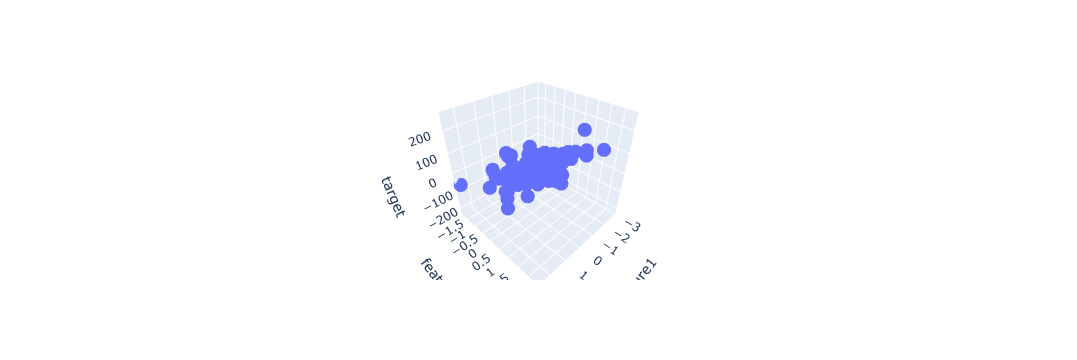

In [7]:
fig = px.scatter_3d(df, x='feature1', y='feature2', z='target')

fig.show()
     

In [8]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=3)

In [9]:
from sklearn.linear_model import LinearRegression
     

In [10]:
lr = LinearRegression()

In [11]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [14]:
y_pred = lr.predict(X_test)

In [15]:
print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2 score",r2_score(y_test,y_pred))
     

MAE 55.57667303487507
MSE 4564.573987764366
R2 score 0.39177886231609704


In [18]:
x = np.linspace(-5, 5, 10)
y = np.linspace(-5, 5, 10)
xGrid, yGrid = np.meshgrid(y, x)
final = np.vstack((xGrid.ravel().reshape(1,100),yGrid.ravel().reshape(1,100))).T
     
z_final = lr.predict(final).reshape(10,10)

z = z_final

#final = np.vstack((xGrid.ravel().reshape(1,100),yGrid.ravel().reshape(1,100))).T
     

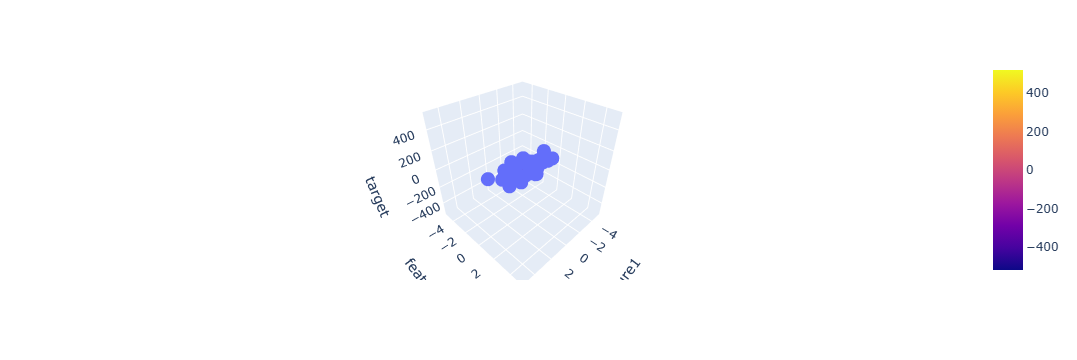

In [19]:
fig = px.scatter_3d(df, x='feature1', y='feature2', z='target')

fig.add_trace(go.Surface(x = x, y = y, z =z ))

fig.show()
     

In [20]:
lr.coef_

array([22.1155546 , 81.98592055])

In [21]:
lr.intercept_


np.float64(-0.3639084673531059)